<a href="https://colab.research.google.com/github/gloria-mbilinyi/gloria-mbilinyi-COU07506-labs/blob/main/COU07506_Week04_240242493088.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WEEK 4 — z-TRANSFORM LABORATORY: POLES, ZEROS AND STABILITY

**Student Name:** Gloria Beneth Mbilinyi  
**Registration Number:** 240242493088  
**Week:** 04  
**Group:** 08  
**Date:** 27/11/2026  
**Module:** COU 07506 — Digital Signal Processing  
**Academic Year:** 2026/2027

### Laboratory Objectives

1. Find poles, zeros, and frequency responses of digital systems.
2. Compute inverse z-transforms using SciPy.
3. Investigate how pole positions affect stability and impulse responses.
4. Design a digital resonator using pole and zero placement.

**Task 4.1: A Pole-Zero Plotting Function**
**Objective:** To determine and visualize the poles and zeros of a digital system and examine its frequency response.

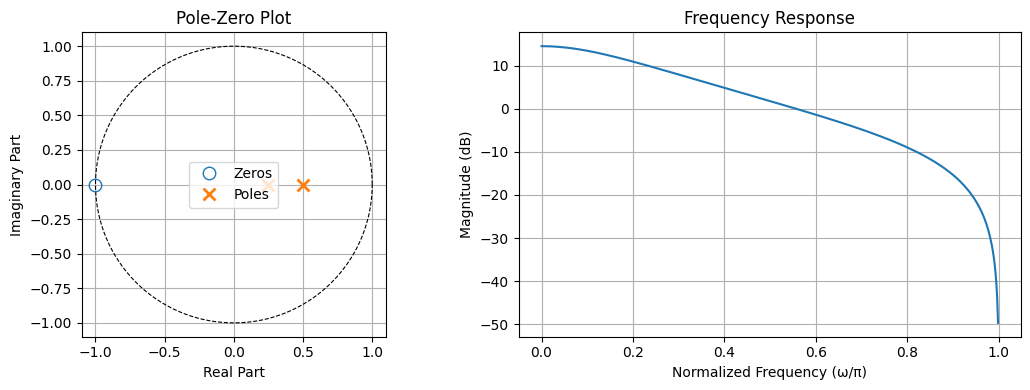

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [1]:

# Task 4.1: A Pole-Zero Plotting Function

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define a function for pole-zero plotting
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    # Draw the unit circle
    theta = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta),
            "k--", linewidth=0.8)

    # Plot zeros and poles
    ax.plot(z.real, z.imag, "o",
            markerfacecolor="none",
            markersize=9, label="Zeros")

    ax.plot(p.real, p.imag, "x",
            markersize=9, markeredgewidth=2,
            label="Poles")

    ax.set_aspect("equal")
    ax.set_xlabel("Real Part")
    ax.set_ylabel("Imaginary Part")
    ax.set_title("Pole-Zero Plot")
    ax.legend()
    ax.grid(True)

    return z, p

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Create subplots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 4)
)

# Plot poles and zeros
zeros, poles = zplane(b, a, ax1)

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Frequency Response")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Display results
print("Zeros:", zeros)
print("Poles:", poles)
print("Stable:", np.all(np.abs(poles) < 1))


### Task 4.1: Results and Discussion

A pole-zero plotting function was implemented using SciPy to examine the stability and frequency response of a discrete-time system.

The system had one zero at −1 and two poles at 0.5 and 0.25. The pole-zero diagram confirmed that both poles were located inside the unit circle, indicating that the causal system is stable.

The frequency-response graph showed that the magnitude decreased as the normalized frequency increased. The zero at −1 produced a null at the Nyquist frequency.

The experiment demonstrated how pole-zero locations can be used to determine system stability and explain frequency-response characteristics.

**Inverse z-Transform with residuez**
**Objective:** To compute an inverse z-transform using partial-fraction expansion and verify the result using SciPy's lfilter() function.

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Partial-fraction result: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
lfilter result: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Results match: True

Task 4.1 system:
Residues: [-5.  6.]
Poles: [0.25 0.5 ]
All three methods match: True


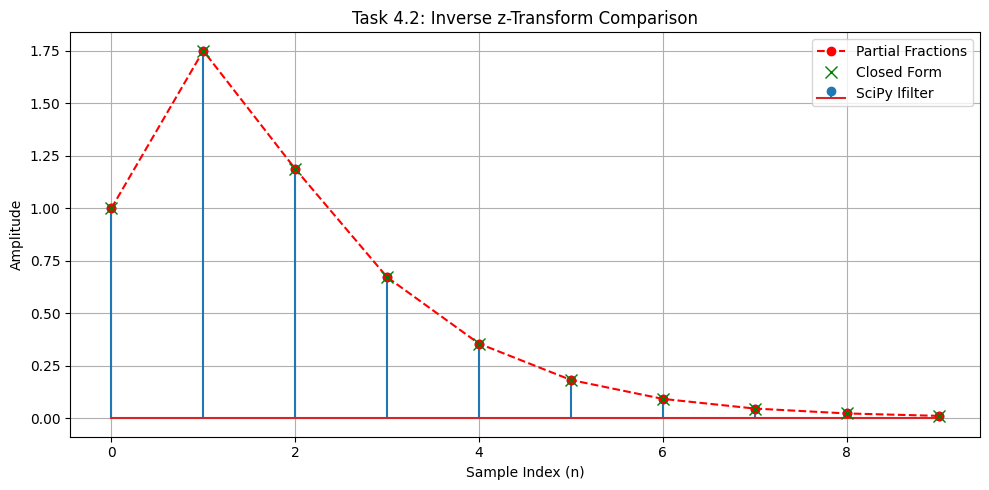

In [2]:

# Task 4.2: Inverse z-Transform with residuez

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System coefficients
b = [1]
a = [1, -0.75, 0.125]

# Partial-fraction expansion
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)

# Generate sample indices
n = np.arange(10)

# Method 1: Partial-fraction expansion
x_pf = sum(
    ri * pi**n for ri, pi in zip(r, p)
).real

# Method 2: Using lfilter
impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(b, a, impulse)

print("Partial-fraction result:", x_pf)
print("lfilter result:", x_lf)
print("Results match:", np.allclose(x_pf, x_lf))

# Repeat for Task 4.1 system
b2 = [1, 1]

r2, p2, k2 = signal.residuez(b2, a)

h_pf = sum(
    ri * pi**n for ri, pi in zip(r2, p2)
).real

h_lf = signal.lfilter(b2, a, impulse)

h_closed = 6*(0.5**n) - 5*(0.25**n)

print("\nTask 4.1 system:")
print("Residues:", r2)
print("Poles:", p2)
print("All three methods match:",
      np.allclose(h_pf, h_lf) and
      np.allclose(h_lf, h_closed))

# Plot comparison
plt.figure(figsize=(10, 5))

plt.stem(n, h_lf, label="SciPy lfilter")
plt.plot(n, h_pf, "ro--",
         label="Partial Fractions")
plt.plot(n, h_closed, "gx",
         markersize=9, label="Closed Form")

plt.title("Task 4.2: Inverse z-Transform Comparison")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Task 4.2: Results and Discussion

The inverse z-transform was computed using SciPy's `residuez()` function and verified using `lfilter()`.

For the first system, the residues were −1 and 2, corresponding to poles at 0.25 and 0.5. The impulse responses calculated using partial fractions and `lfilter()` were identical.

The experiment was repeated using the system from Task 4.1. The residues obtained were −5 and 6, with poles at 0.25 and 0.5.

The partial-fraction method, `lfilter()`, and closed-form expression produced matching impulse responses, as confirmed by the numerical comparison and overlapping graphs.

The results demonstrate that partial-fraction expansion provides an accurate method for computing the inverse z-transform of discrete-time systems.

**Task 4.3 — Pole Position and the Impulse Response**

**Objective:** To investigate how changing pole positions affects impulse-response decay, oscillation, resonance, and system stability.

r = 0.5
Poles = [0.3536+0.3536j 0.3536-0.3536j]
BIBO Stable = True
---------------------------
r = 0.8
Poles = [0.5657+0.5657j 0.5657-0.5657j]
BIBO Stable = True
---------------------------
r = 0.95
Poles = [0.6718+0.6718j 0.6718-0.6718j]
BIBO Stable = True
---------------------------
r = 1.0
Poles = [0.7071+0.7071j 0.7071-0.7071j]
BIBO Stable = False
---------------------------
r = 1.05
Poles = [0.7425+0.7425j 0.7425-0.7425j]
BIBO Stable = False
---------------------------


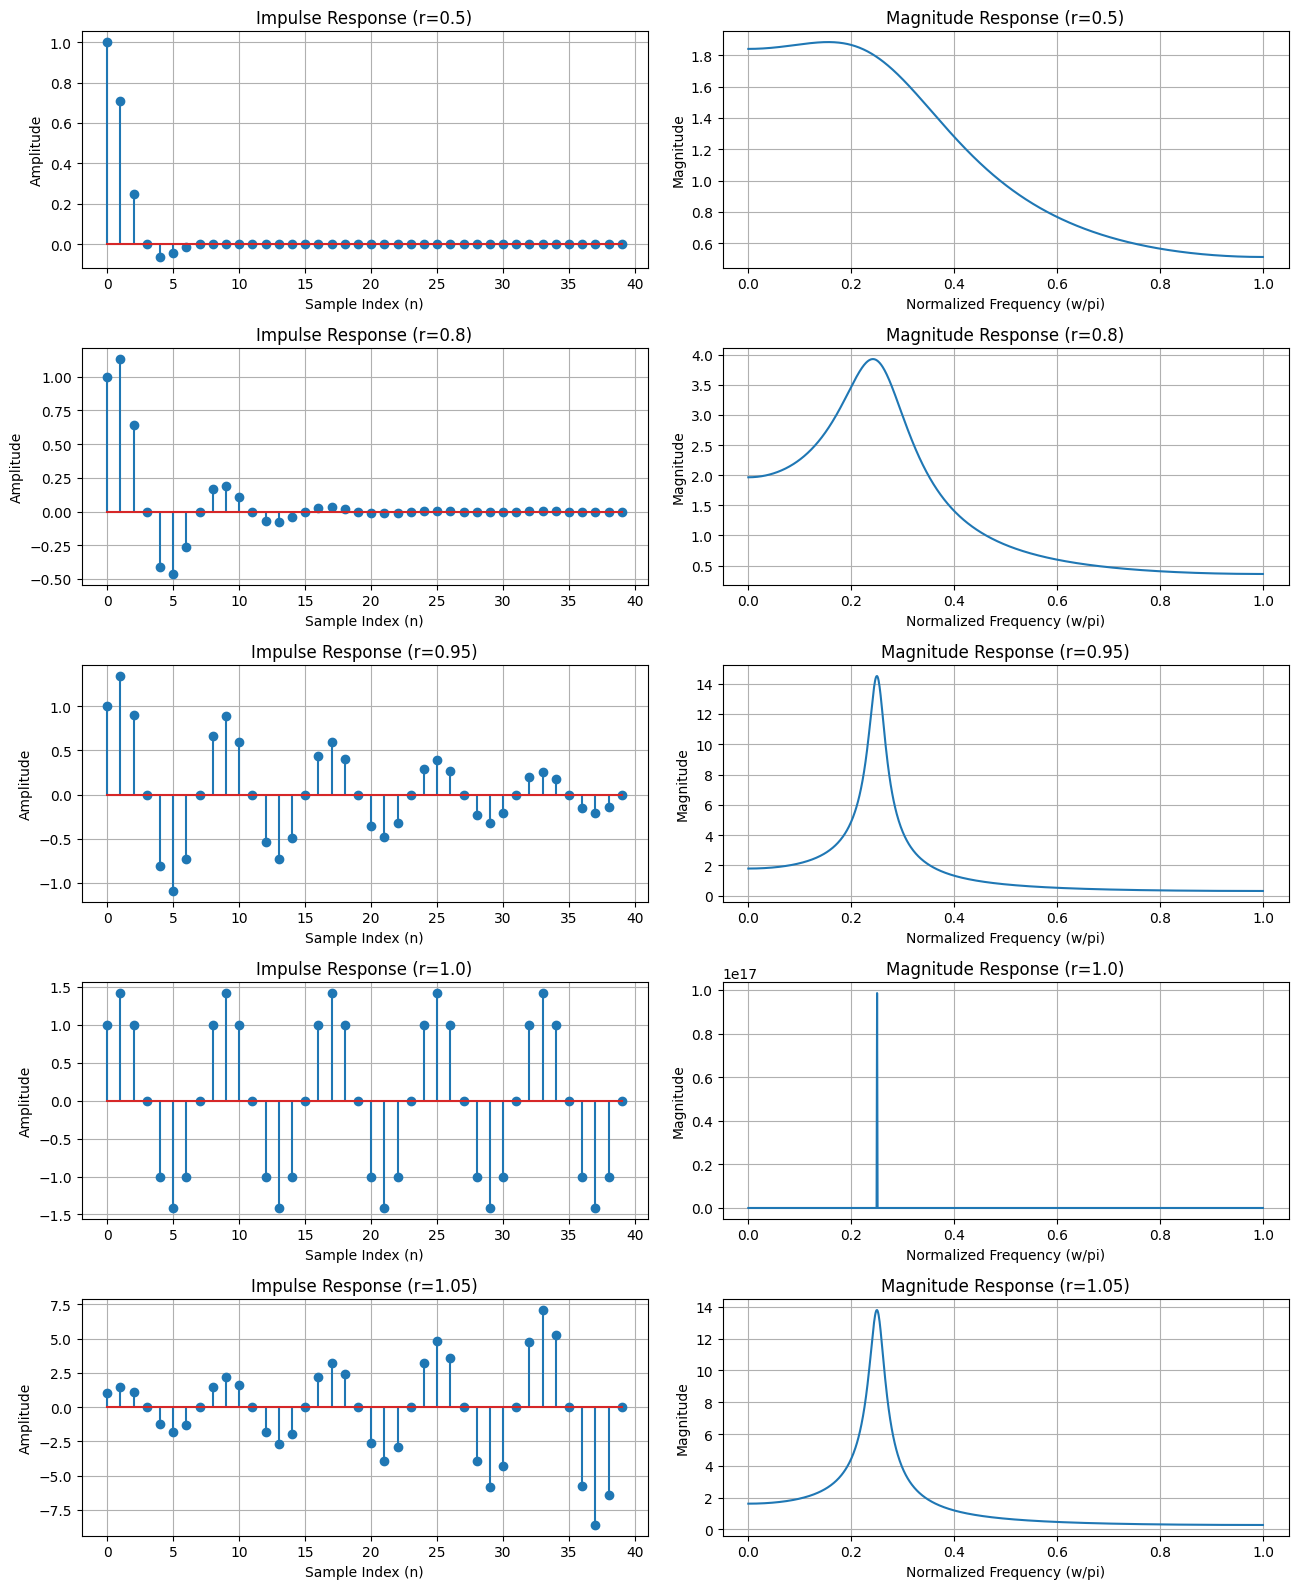

In [3]:

# Task 4.3: Pole Position and Impulse Response

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4

N = 40
n = np.arange(N)

impulse = np.zeros(N)
impulse[0] = 1

fig, axes = plt.subplots(5, 2, figsize=(13, 16))

for i, r in enumerate(r_values):

    # System coefficients
    b = [1]
    a = [1, -2*r*np.cos(theta), r**2]

    # Calculate poles
    poles = np.roots(a)

    # Impulse response
    h = signal.lfilter(b, a, impulse)

    # Frequency response
    w, H = signal.freqz(b, a, worN=1024)

    # Plot impulse response
    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse Response (r={r})")
    axes[i, 0].set_xlabel("Sample Index (n)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True)

    # Plot frequency response
    axes[i, 1].plot(w/np.pi, np.abs(H))
    axes[i, 1].set_title(f"Magnitude Response (r={r})")
    axes[i, 1].set_xlabel("Normalized Frequency (w/pi)")
    axes[i, 1].set_ylabel("Magnitude")
    axes[i, 1].grid(True)

    # Stability check
    stable = np.all(np.abs(poles) < 1)

    print(f"r = {r}")
    print(f"Poles = {np.round(poles, 4)}")
    print(f"BIBO Stable = {stable}")
    print("---------------------------")

plt.tight_layout()
plt.show()


### Task 4.3: Results and Discussion

The effect of pole position on the impulse response and frequency response was investigated using five pole radii: 0.5, 0.8, 0.95, 1.0, and 1.05.

For r = 0.5, the impulse response decayed rapidly, indicating a stable system with relatively weak resonance. When the radius increased to 0.8, the oscillations persisted longer and the resonance became more pronounced.

At r = 0.95, the impulse response decayed slowly and the frequency response showed a sharp resonance peak.

For r = 1.0, the poles were located on the unit circle, resulting in sustained oscillations without decay. The system was not BIBO stable.

At r = 1.05, the poles were outside the unit circle, causing the oscillations to grow in amplitude. This indicated an unstable system.

The results demonstrate that pole positions significantly affect the stability, decay rate, and frequency response of a discrete-time system. As the poles approach the unit circle from inside, the resonance becomes sharper and the impulse response decays more slowly.

**Task 4.4 — Stability of Given Systems**

**Objective:** To determine whether four discrete-time systems are stable or unstable by examining their pole locations and impulse responses


H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
BIBO Stable: True
-----------------------------------

H2
Zeros: [-1.]
Poles: [2.  0.5]
BIBO Stable: False
-----------------------------------

H3
Zeros: []
Poles: [-1.   0.5]
BIBO Stable: False
-----------------------------------

H4
Zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
Poles: []
BIBO Stable: True
-----------------------------------


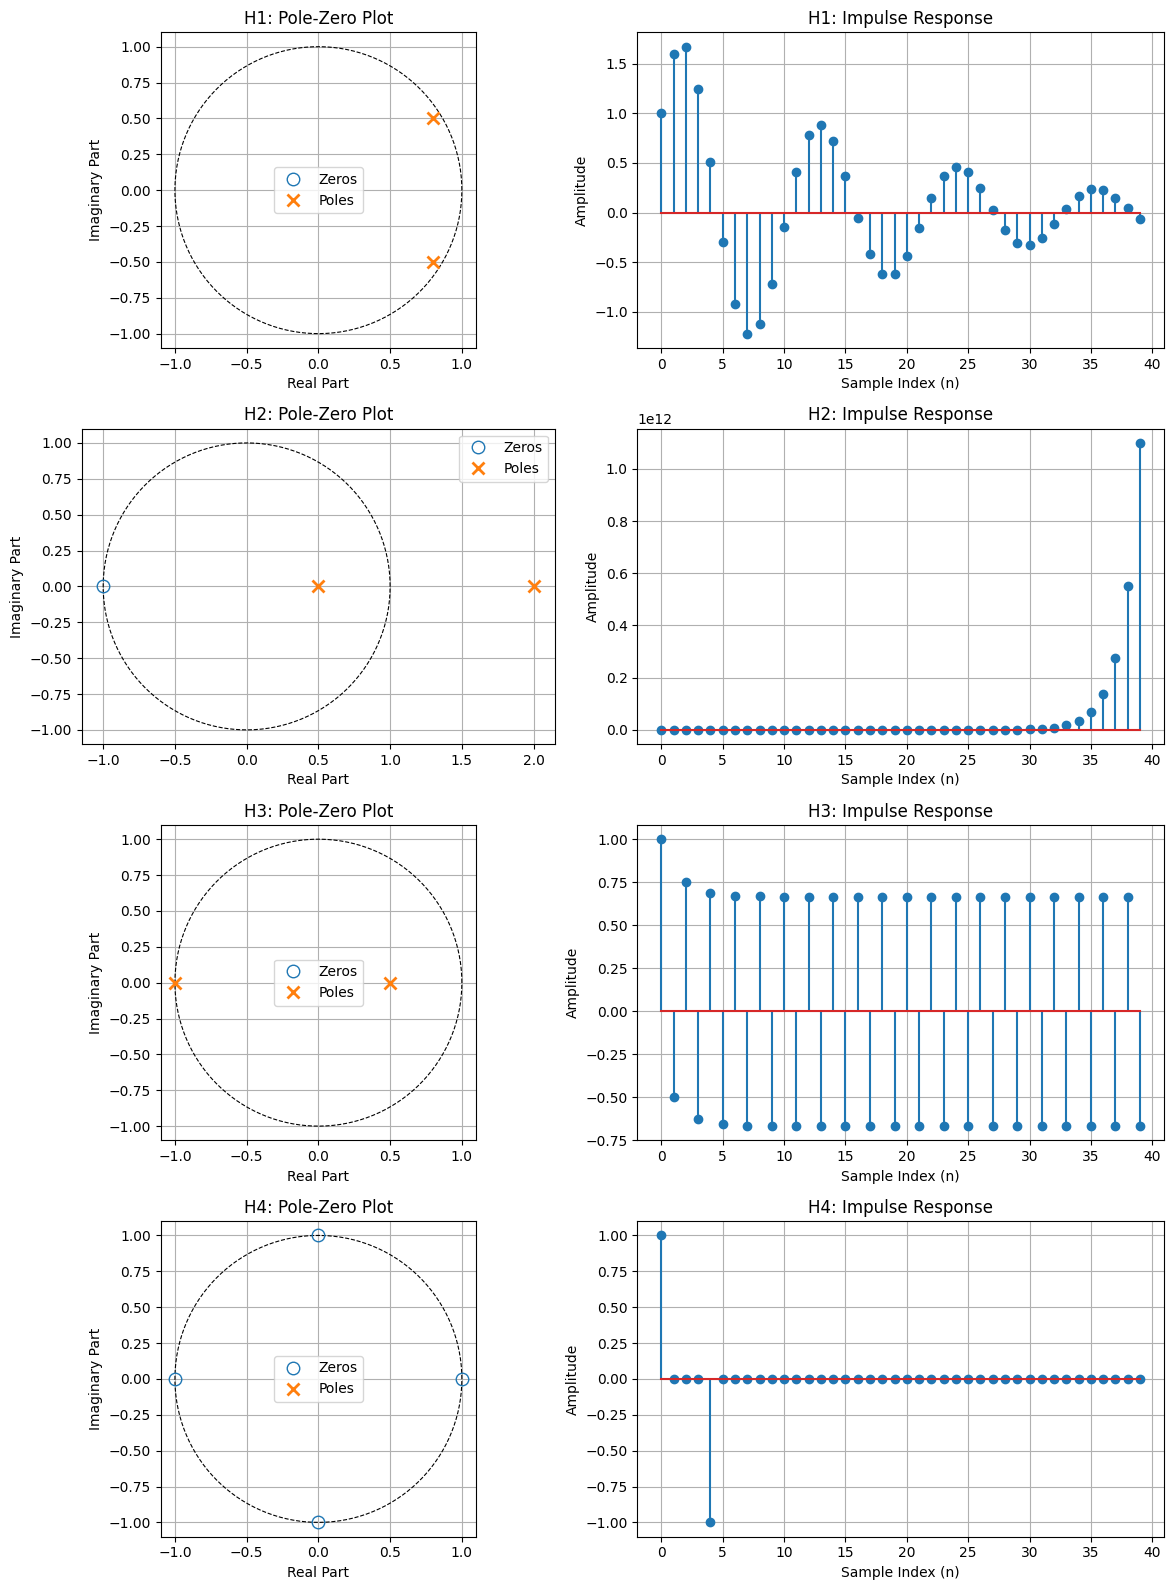

In [4]:

# Task 4.4: Stability of Given Systems

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define the four systems from the manual
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

N = 40
n = np.arange(N)

impulse = np.zeros(N)
impulse[0] = 1

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, (name, (b, a)) in enumerate(systems.items()):

    # Find zeros and poles
    zeros, poles, gain = signal.tf2zpk(b, a)

    # Check BIBO stability
    stable = np.all(np.abs(poles) < 1)

    # Generate impulse response
    h = signal.lfilter(b, a, impulse)

    # Pole-zero diagram
    zplane(b, a, axes[i, 0])
    axes[i, 0].set_title(f"{name}: Pole-Zero Plot")

    # Impulse response
    axes[i, 1].stem(n, h)
    axes[i, 1].set_title(f"{name}: Impulse Response")
    axes[i, 1].set_xlabel("Sample Index (n)")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid(True)

    print(f"\n{name}")
    print("Zeros:", np.round(zeros, 4))
    print("Poles:", np.round(poles, 4))
    print("BIBO Stable:", stable)
    print("-" * 35)

plt.tight_layout()
plt.show()


### Task 4.4: Results and Discussion

The stability of four discrete-time systems was investigated by examining their pole-zero diagrams and impulse responses.

**System H1:** The poles were located inside the unit circle. Its impulse response showed decaying oscillations, indicating that the system was stable.

**System H2:** One pole was located outside the unit circle at 2.0. The impulse response increased significantly with time, indicating an unstable system.

**System H3:** One pole was located on the unit circle at −1. The impulse response continued oscillating without decaying to zero, indicating that the system was not BIBO stable.

**System H4:** The system had a finite impulse response with only two nonzero samples. It was classified as a stable FIR system.

The experiment demonstrated that the locations of poles are important when determining the stability of digital systems. For causal systems with no unstable pole-zero cancellations, poles must lie strictly inside the unit circle for BIBO stability.

**Task 4.5 — Design a Resonator**

**Objective:** To design a second-order digital resonator with a resonant frequency of 1 kHz, a sampling rate of 8 kHz, and a pole radius of 0.97.

Sampling frequency: 8000 Hz
Target resonant frequency: 1000 Hz
Pole radius: 0.97
Zeros: [-1.  1.]
Poles: [0.6859+0.6859j 0.6859-0.6859j]
BIBO Stable: True
Measured peak frequency: 1000.98 Hz


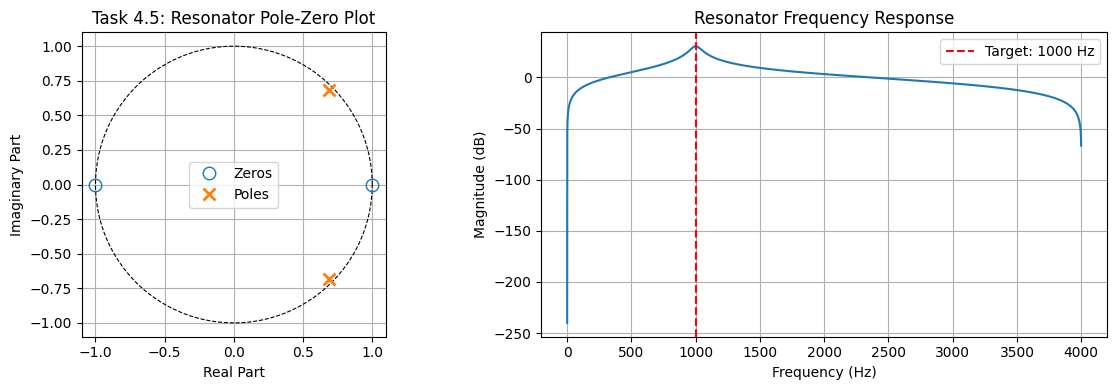


Original White Noise:


Filtered Resonator Output:


In [5]:

# Task 4.5: Design a Resonator

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Resonator specifications
fs = 8000
f0 = 1000
r = 0.97

# Pole angle
theta = 2 * np.pi * f0 / fs

# Zeros at z = +1 and z = -1
b = [1, 0, -1]

# Resonator denominator
a = [1, -2*r*np.cos(theta), r**2]

# Calculate zeros and poles
zeros, poles, gain = signal.tf2zpk(b, a)

print("Sampling frequency:", fs, "Hz")
print("Target resonant frequency:", f0, "Hz")
print("Pole radius:", r)
print("Zeros:", np.round(zeros, 4))
print("Poles:", np.round(poles, 4))
print("BIBO Stable:", np.all(np.abs(poles) < 1))

# Frequency response
freq, H = signal.freqz(b, a, worN=4096, fs=fs)

peak_frequency = freq[np.argmax(np.abs(H))]
print("Measured peak frequency:",
      round(peak_frequency, 2), "Hz")

# Plot pole-zero diagram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

zplane(b, a, axes[0])
axes[0].set_title("Task 4.5: Resonator Pole-Zero Plot")

# Plot frequency response
axes[1].plot(freq, 20*np.log10(
    np.maximum(np.abs(H), 1e-12)
))

axes[1].axvline(
    f0, color="red", linestyle="--",
    label="Target: 1000 Hz"
)

axes[1].set_title("Resonator Frequency Response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Apply the resonator to white noise
rng = np.random.default_rng(0)
noise = rng.standard_normal(fs * 2)

# Filter white noise
y = signal.lfilter(b, a, noise)

# Normalize audio for listening
y_audio = y / max(np.max(np.abs(y)), 1e-12)

print("\nOriginal White Noise:")
display(Audio(noise, rate=fs))

print("Filtered Resonator Output:")
display(Audio(y_audio, rate=fs))


### Task 4.5: Results and Discussion

A second-order digital resonator was designed using a sampling frequency of 8,000 Hz, a target resonant frequency of 1,000 Hz, and a pole radius of 0.97.

The pole-zero diagram showed two complex-conjugate poles at approximately 0.6859 ± 0.6859j, together with zeros at −1 and +1. Since both poles were inside the unit circle, the resonator was BIBO stable.

The frequency response showed a strong resonance peak at 1,000.98 Hz, which was very close to the target frequency. The zeros attenuated the frequency response at DC and the Nyquist frequency.

The resonator was also applied to white noise, and the original and filtered audio outputs were generated for listening comparison.

The results demonstrate how pole and zero placement can be used to design a stable resonator that emphasizes a selected frequency while attenuating unwanted frequency components.

### Listening Observation

After listening to both audio recordings, I noticed a clear difference between the original white noise and the filtered resonator output.

The original white noise contained a broad range of frequencies, while the filtered output had a more noticeable resonant sound.

This difference occurred because the resonator emphasized frequencies near 1 kHz while attenuating other frequency components.

The listening experiment confirmed the frequency-selective behaviour observed in the resonator's frequency-response graph.

## WEEK 4 — PRE-LAB QUESTIONS

### Question 1: Find the poles of H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²) and determine whether the system is stable.

**Answer:**

The poles are obtained by finding the roots of the denominator.

The calculated poles are:

- p₁ = 0.45 + 0.7794j
- p₂ = 0.45 − 0.7794j

Both poles have a magnitude of 0.9, meaning they lie inside the unit circle.

Therefore, assuming a causal system, **the system is BIBO stable**.

### Question 2: Write the partial-fraction expansion of X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)].

**Answer:**

The partial-fraction expansion is:

X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹)

The residues are 2 and −1, corresponding to poles at 0.5 and 0.25 respectively.

These results were verified in Task 4.2 using SciPy's `residuez()` function.

## WEEK 4 — ANALYSIS QUESTIONS

### Question 1: Explain the effect of r on the bandwidth of the resonance in Task 4.3.

**Answer:**

The pole radius determines how sharply a digital system responds around its resonant frequency.

When the pole radius is small, such as r = 0.5, the impulse response decays quickly and the resonance is relatively broad.

As the pole radius increases to 0.8 and 0.95, the impulse response decays more slowly and the resonance becomes sharper, resulting in a narrower bandwidth.

At r = 1.0, oscillations continue without decaying, while at r = 1.05, their amplitude increases with time.

Therefore, increasing the pole radius toward the unit circle reduces the resonance bandwidth and increases the persistence of oscillations.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

**Answer:**

When a pole lies exactly on the unit circle, the corresponding impulse-response component does not decay with time.

For the simple complex-conjugate poles tested in Task 4.3 at r = 1.0, the impulse response continued oscillating with a constant amplitude envelope.

Since these oscillations do not decay, the impulse response is not absolutely summable, and the causal system is not BIBO stable.

This behaviour was confirmed by the numerical results, which classified r = 1.0 as unstable under the BIBO stability criterion.

### Question 3: Why does placing zeros at z = ±1 make the resonator a band-pass filter?

**Answer:**

Placing a zero at z = +1 causes the frequency response to become zero at DC (0 Hz).

Placing another zero at z = −1 causes the response to become zero at the Nyquist frequency, which is 4,000 Hz for a sampling frequency of 8,000 Hz.

These zeros suppress the lowest and highest frequencies in the digital frequency range.

The resonator poles emphasize frequencies near the selected resonance of 1 kHz, allowing a narrow range of frequencies to pass more strongly.

In Task 4.5, the measured resonance peak was 1,000.98 Hz, which was very close to the target frequency.

Therefore, the combination of the zeros and resonant poles produces a band-pass response.

### Question 4: Use the stability triangle to check your answers to Task 4.4 (a)–(c).

**Answer:**

The stability triangle was used to verify the stability of the three second-order systems.

**System H1:**

The stability conditions give positive values of 0.29, 3.49, and 0.11.

All three conditions are satisfied.

**Result: Stable.**

**System H2:**

The stability conditions give −0.50, 4.50, and 0.

The conditions are not all strictly positive, and the system has a pole outside the unit circle.

**Result: Unstable.**

**System H3:**

The stability conditions give 1.00, 0, and 1.50.

One condition is equal to zero, indicating a pole on the unit circle.

**Result: Not BIBO stable.**

The stability triangle results agree with the pole-zero diagrams and impulse responses obtained in Task 4.4.

## CONCLUSION

In this laboratory, I investigated the z-transform, pole-zero locations, impulse responses, and stability of discrete-time systems using Python in Google Colab.

I successfully implemented a pole-zero plotting function and examined the relationship between pole locations and system stability. I also calculated inverse z-transforms using partial-fraction expansion and verified the results using SciPy's `lfilter()` function.

The experiments demonstrated that poles inside the unit circle produce stable causal systems, while poles on or outside the unit circle can result in sustained or growing responses.

I also designed a second-order digital resonator with a target frequency of 1 kHz. The measured resonance peak was 1,000.98 Hz, and the system was confirmed to be stable.

The listening experiment showed an audible difference between the original white noise and the filtered resonator output, demonstrating frequency-selective filtering.

Overall, the laboratory improved my understanding of digital system stability, resonance, and the practical applications of the z-transform in digital signal processing.

## AI-USE STATEMENT

I used ChatGPT to assist with understanding the laboratory instructions, explaining Python code, troubleshooting, and interpreting the experimental results.

I verified the results by executing the Python programs in Google Colab, examining the pole-zero diagrams and frequency-response graphs, comparing numerical results with theoretical expectations, and listening to the processed audio signals.